# ShiftRoute-RL v0.3/v0.5: Independent numerical audit

**Scope:** Synthetic offline research experiments only. This notebook reproduces calculations from the saved v0.3 stream simulations and v0.5 paired trajectory counterexample. It does **not** validate a production safety guarantee, monetary savings, scientific novelty, or pretrained LLM generalization.

## Research question
Can policy-adaptive verification reduce expensive review without increasing unauthorized executions? We separate **fixed-proposal** comparisons from **endogenous-trajectory** effects.

### Key assumptions
- v0.3 reviewer and authorization labels are artificially generated; its strong proof-positive case assumes sound independent certificates.
- v0.3 seed replication varies **stream randomness**, but does not repeat end-to-end policy training for every stream seed (PPO policy seed 7 reused).
- v0.5 reviewer errors are independent Bernoulli variables in a two-stage simulator; the stateful shield is idealized.
- Confidence intervals for 200,000 v0.5 episodes cover only *simulator Monte Carlo uncertainty*, not external validity.

In [1]:
import json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root=Path.cwd()
v3=json.loads((root/'results/v03/experiment.json').read_text())
v5=json.loads((root/'results/v05/endogenous_counterexample.json').read_text())
df=pd.DataFrame(v3['records'])
assert len(df)==150 and len(df.stream_seed.unique())==5
assert v5['config']['episodes']==200000
print('Validated inputs:',len(df),'v0.3 method/stream observations,',v5['config']['episodes'],'v0.5 episodes')

Validated inputs: 150 v0.3 method/stream observations, 200000 v0.5 episodes


## v0.3: Paired fixed-stream comparisons

The compared methods share policy-selected candidate actions and reviewer random coins in each scenario. The rates below are measured per proposed action, not per adaptive trajectory.

In [2]:
subset=df[(df.regime=='joint-shift') & (df.reviewer_sensitivity==1.)]
summary=subset.groupby('mode').agg(unsafe_mean=('unsafe_executed_fraction','mean'),
                                  unsafe_std=('unsafe_executed_fraction','std'),
                                  review_mean=('review_fraction','mean'),
                                  cost_mean=('review_cost_per_action','mean'),
                                  stream_seeds=('stream_seed','nunique')).sort_values('cost_mean',ascending=False)
assert summary.loc['all','unsafe_mean']==summary.loc['proof','unsafe_mean']==0.
print(summary.round(4).to_string())

           unsafe_mean  unsafe_std  review_mean  cost_mean  stream_seeds
mode                                                                    
all             0.0000      0.0000       1.0000     1.0250             5
adaptive        0.0653      0.0074       0.7313     0.7563             5
proof           0.0000      0.0000       0.6953     0.7303             5
sentinel        0.4125      0.0009       0.1550     0.1800             5
threshold       0.4696      0.0028       0.0432     0.0682             5


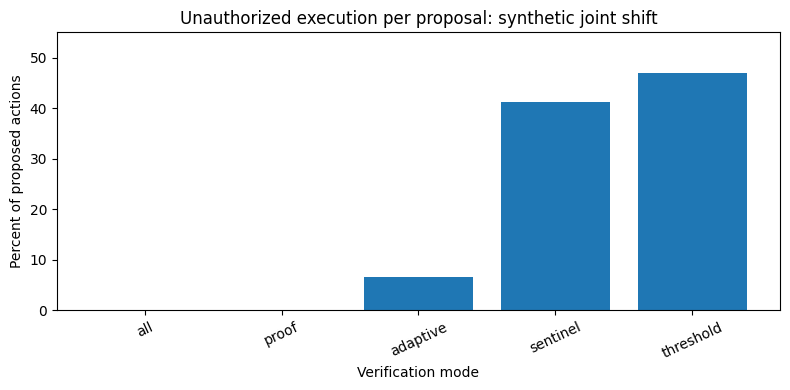

In [3]:
fig,ax=plt.subplots(figsize=(8,4))
plot=summary.sort_values('unsafe_mean')
ax.bar(plot.index,plot.unsafe_mean*100)
ax.set_title('Unauthorized execution per proposal: synthetic joint shift')
ax.set_ylabel('Percent of proposed actions')
ax.set_xlabel('Verification mode')
ax.set_ylim(0,55)
plt.xticks(rotation=25)
fig.tight_layout()
plt.show()

## v0.5: The missing trajectory feedback effect

Reviewing an authorized unlock can falsely deny it, stopping future proposals. Sound proof-first bypass permits unlock and therefore encounters an additional, potentially unauthorized proposal. In the synthetic model with legitimate-action false denial probability f and later unsafe-action review miss probability m, additional episode-level unsafe probability equals **f × m**.

In [4]:
f=v5['config']['false_denial_probability']
m=v5['config']['unsafe_miss_probability']
rows=pd.DataFrame(v5['results'])
assert math.isclose(v5['exact_theoretical_risk_increase'],f*m)
assert v5['paired_risk_increase_ci95'][0] <= f*m <= v5['paired_risk_increase_ci95'][1]
print('Analytic delta:',round(f*m*100,4),'percentage points')
print('Paired MC delta:',round(v5['paired_risk_increase']*100,4),'percentage points')
print('Wilson 95% interval in percentage points:',[round(100*x,4) for x in v5['paired_risk_increase_ci95']])
print(rows[['method','unsafe_episode_rate','reviewer_calls_per_episode','cost_units_per_episode']].to_string(index=False))

Analytic delta: 1.2 percentage points
Paired MC delta: 1.1815 percentage points
Wilson 95% interval in percentage points: [1.1351, 1.2298]
                          method  unsafe_episode_rate  reviewer_calls_per_episode  cost_units_per_episode
                      verify_all             0.067960                     1.85008                 1.85008
               sound_proof_first             0.079775                     1.00000                 1.01000
sound_proof_plus_stateful_shield             0.000000                     1.00000                 1.03000


## Interpretation and decision

1. **Do not claim universal safety equivalence** from fixed-stream proof-first results; the v0.5 counterexample disproves it under endogenous gate-policy feedback.
2. A stateful, independently sound authorization gate could prevent this constructed misuse, but this shifts the burden to the gate's formal completeness/correctness and its operational costs.
3. Publishing a validated new method requires external multi-turn agent benchmarks, proof-soundness stress tests, strong contemporary baselines (e.g., CSA and GRAFT), multiple training seeds and observed real reviewer costs.

**Evidence references:** `docs/research-v03.md`, `docs/research-v05.md`; [Verifier Errors in RLVR](https://arxiv.org/abs/2609.35677), [CSA](https://arxiv.org/abs/2605.20270), [GRAFT](https://alignment.anthropic.com/2026/graft/).